# Real-image spatial opacity reconstruction

## 1. Problem

Recover the complete spatial foreground-opacity field from a real RGB photograph and an independent coarse hand-drawn trimap despite ambiguous foreground-background mixing and fine hair boundaries.

The benchmark reconstructs every native opacity pixel from a real CC0 lemur photograph and an independently authored manual trimap. Mixed foreground/background colors make this a spatial inverse compositing problem rather than binary classification. Gray annotation means unknown, not measured opacity. There is no independently measured opacity truth; reproduced original-method arrays are labeled references.


## 2. Data

`data/raw_data.npz` contains the real photograph and its independently authored trimap, converted losslessly from the source's 8-bit images to the declared normalized float64 values. Neither a target opacity field nor foreground/background estimates are visible inputs.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| image | (1, 440, 680, 3) | float64 | Observed encoded RGB photograph, dimensionless values equal to original 8-bit channel codes divided by 255; channel order red, green, blue |
| trimap | (1, 440, 680) | float64 | Independent manual labels, dimensionless: 0 background, 1 foreground, 0.4 unknown |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Observation origin | Real photograph | dimensionless | No new synthetic observation or noise realization is generated |
| Native rows | 440 | pixel | Complete released image height |
| Native columns | 680 | pixel | Complete released image width |
| Color order | RGB | dimensionless | Last array axis is red, green, blue |
| Color encoding | Original 8-bit photographic RGB codes divided by 255 | dimensionless | Preserve source encoding; no linear-light or absolute flux conversion |
| Known opacity labels | 0 and 1 | dimensionless | Independent background and foreground annotations |
| Unknown annotation | 0.4 | dimensionless label | No opacity value is specified at these pixels |
| Unconstrained pixels | 38666 | pixel | Number of unknown trimap labels |
| Coordinates | Row down, column right, top-left origin | pixel | Original array coordinates, no physical length calibration |
| Image boundary | Finite image, no periodic extension | dimensionless | No observations beyond the supplied image are assumed |
| Sensor noise | Unspecified photographic acquisition noise | encoded RGB unit | No calibrated variance or added noise is supplied |

The photograph is by Mathias Appel, released under CC0 1.0. The manual trimap is supplied with the associated research implementation. This is a real-image reconstruction with manual constraints, not a simulated opacity benchmark.


## 3. Physics

The observation is the full native lemur photograph, accompanied by the source's independent manual trimap. For each row-major pixel i, the nominal compositing model is


$$
I_i=\alpha_i F_i+(1-\alpha_i)B_i.
$$


Here I is the observed three-channel RGB vector, F and B are unknown foreground and background RGB vectors in the same dimensionless encoded color scale, and alpha is foreground opacity in [0,1]. The requested unknown is the complete spatial opacity field; F and B are nuisance fields, not supplied observations. The usual linear mixture is an approximation in encoded photographic RGB, so no absolute radiometric opacity calibration is implied.

The independent trimap supplies exact opacity 0 at background labels and 1 at foreground labels. Its gray value 0.4 identifies an unknown pixel and is **not** an opacity observation. Most ambiguous pixels lie near the object's hair and boundary. The inverse is underdetermined because one observed RGB vector permits many combinations of alpha, F and B. Spatial/color assumptions and the stated constraints are necessary to obtain a useful field.


## 4. Method

### Physics, nuisance variables and the selected inverse

The nominal encoded-RGB mixture is $I_i=\alpha_iF_i+(1-\alpha_i)B_i$, where $I_i,F_i,B_i$ are three-channel dimensionless photographic codes and $\alpha_i$ is opacity. This is a linear approximation in encoded photographic RGB, not calibrated optical flux. In a complete nine-pixel window $w$, use the color-line model $\alpha_i\approx a_w^TI_i+b_w$, with local three-vector $a_w$ and scalar $b_w$. Minimize squared affine residuals plus $\epsilon\lVert a_w\rVert^2$; eliminating these nuisance coefficients gives $\alpha^TL\alpha$.

For window mean $\mu_w$, color covariance $\Sigma_w$ and nine pixels, its Laplacian contribution is


$$
L^{w}_{ij}=\delta_{ij}-\frac{1+(I_i-\mu_w)^T(\Sigma_w+\epsilon I_3/9)^{-1}(I_j-\mu_w)}{9}.
$$


Here $\delta$ is the Kronecker indicator and $I_3$ the identity. Only complete windows inside the finite image contribute; there is no padding. $L$ is symmetric positive semidefinite and has a constant null vector. Known trimap labels fix a solution: with known/unknown partitions $K,U$, solve $L_{UU}\alpha_U=-L_{UK}\alpha_K$. Evaluate local covariance regularization at $\epsilon=10^{-7}$, use original documented Jacobi-preconditioned CG, zero initialization, relative residual tolerance $10^{-7}$ and a 10000-update budget. The bound path takes 1350 updates. Clip to [0,1] only after the unconstrained solve, matching the original implementation; this is not a box-constrained KKT solve.

The original default incomplete-Cholesky run is a separately identified numerical control. It changes solver acceleration, not acquisition or the variational problem. Independent matrix/iteration fixtures and Schur/gradient physics tests supplement reference agreement.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
T=Path.cwd()
if T.name=='notebooks': T=T.parent
if not (T/'data/raw_data.npz').exists(): raise RuntimeError('Run from this task or its notebooks directory')
os.chdir(T)
sys.path.insert(0,str(T))
from src.main import run
from src.preprocessing import load_data
from src.visualization import make_figures,export_figures
image,trimap=load_data()
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as z: reference=z['reconstruction'][0]
with np.load('notebooks/reference_outputs/default_ichol_measurements.npz',allow_pickle=False) as z:
    default_reference=z['reconstruction'][0];default_history=z['history']
source_measurements=json.loads(Path('notebooks/reference_outputs/measurements.json').read_text(encoding='utf8'))
print('Actual original runs:',source_measurements)
print('Real observations:',image.shape,'independent manual labels:',np.unique(trimap))


Actual original runs: {'selected': {'runtime_seconds': 0.5985900000014226, 'iterations': 1350, 'last_recursive_residual': [1350, 6.6410257977708626e-06, 9.939294383071883e-08], 'max_difference_default_ichol': 3.822980819323529e-05, 'relative_l2_difference_default_ichol': 2.679236260022633e-06, 'source_revision': '6d5c4a6bed0e5672abac0bad078e594423ffe4fd', 'selected_configuration': 'original estimate_alpha_cf with documented original jacobi preconditioner; epsilon1e-7 radius1 CG rtol1e-7 maxiter10000 zero initialization', 'parity_criteria': {'laplacian_rtol': 1e-08, 'laplacian_atol': 1e-11, 'stage_rtol': 1e-07, 'stage_atol': 1e-08, 'full_field_relative_l2': 1e-06}, 'selected_before_local_extraction': True}, 'default': {'runtime_seconds': 0.5588606999954209, 'shape': [440, 680], 'unknown_pixels': 38666, 'iterations': 6, 'last_recursive_residual': [6, 6.340822069976835e-06, 9.489994332702861e-08], 'explicit_unclipped_residual': None, 'numpy': '2.4.6', 'scipy': '1.17.1', 'numba': '0.68.0',

### Active complete native reconstruction and independent evaluation

The following calls the cleaned standard entry point on the public observations, recomputes the complete opacity field and evaluates that fresh file. The original reference is used only for comparisons, never as a reconstruction input. No cache-preview path is selected.


In [2]:
start=time.perf_counter()
alpha,diagnostics=run()
active_seconds=time.perf_counter()-start
from src.solvers import reconstruct
_,stage_diagnostics=reconstruct(image,trimap,capture_steps=[1,10,100])
diagnostics['captured']=stage_diagnostics['captured']
command=[sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json']
judged=subprocess.run(command,cwd=T,capture_output=True,text=True)
report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judged.returncode==0,report
print('Fresh complete reconstruction seconds:',active_seconds)
print(json.dumps(report,indent=2))
assert np.array_equal(alpha,reference)


Fresh opacity: 0.706486s; CG iterations 1350; relative residual 9.93929441383e-08


Fresh complete reconstruction seconds: 0.7211121999935131
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 0.0,
    "known_pixel_max_error": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "known_pixel_max_error": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}


### Actual comparisons, boundary information and numerical sensitivity

All fresh plots below are computed from local modules. Reproduced original Jacobi and default incomplete-Cholesky arrays come from the exact same native photograph/trimap and are explicitly identified. Hard thresholding is an actual approximation of the newly computed alpha, not an independent segmentation result or ground truth. Two additional covariance regularizers are actively reconstructed; their changes are sensitivity evidence rather than calibrated uncertainty. Native detail panels have the same pixel region and opacity scales. Original covariance/CSR accumulation order is preserved because changing sums by a few machine epsilons affects late CG conjugacy on this ill-conditioned problem.


{
  "iterations": 1350,
  "explicit_relative_residual": 9.939294413831125e-08,
  "source_max_difference": 0.0,
  "source_relative_l2": 0.0,
  "unknown_pixels": 38666,
  "known_pixel_error": 0.0,
  "sensitivity": [
    {
      "epsilon": 1e-05,
      "seconds": 0.8891137999962666,
      "iterations": 769,
      "rms_change": 0.009819253831829874,
      "explicit_relative_residual": 9.798554745507729e-08
    },
    {
      "epsilon": 0.001,
      "seconds": 0.7079267000008258,
      "iterations": 349,
      "rms_change": 0.046705411591465656,
      "explicit_relative_residual": 9.463714119092604e-08
    }
  ],
  "active_standard_seconds": 0.7211121999935131
}


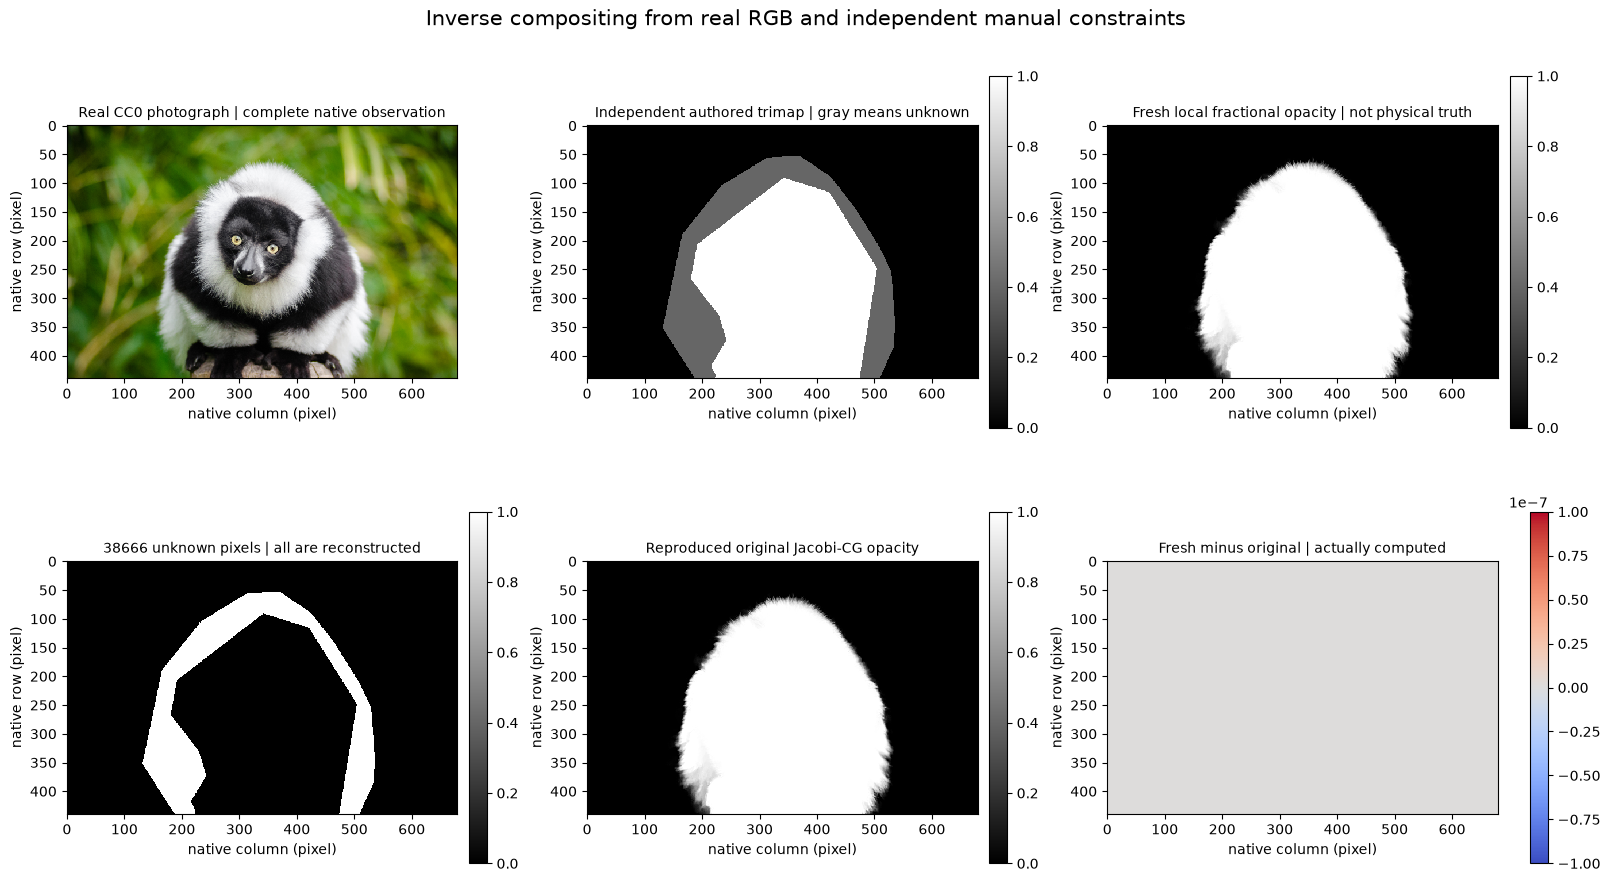

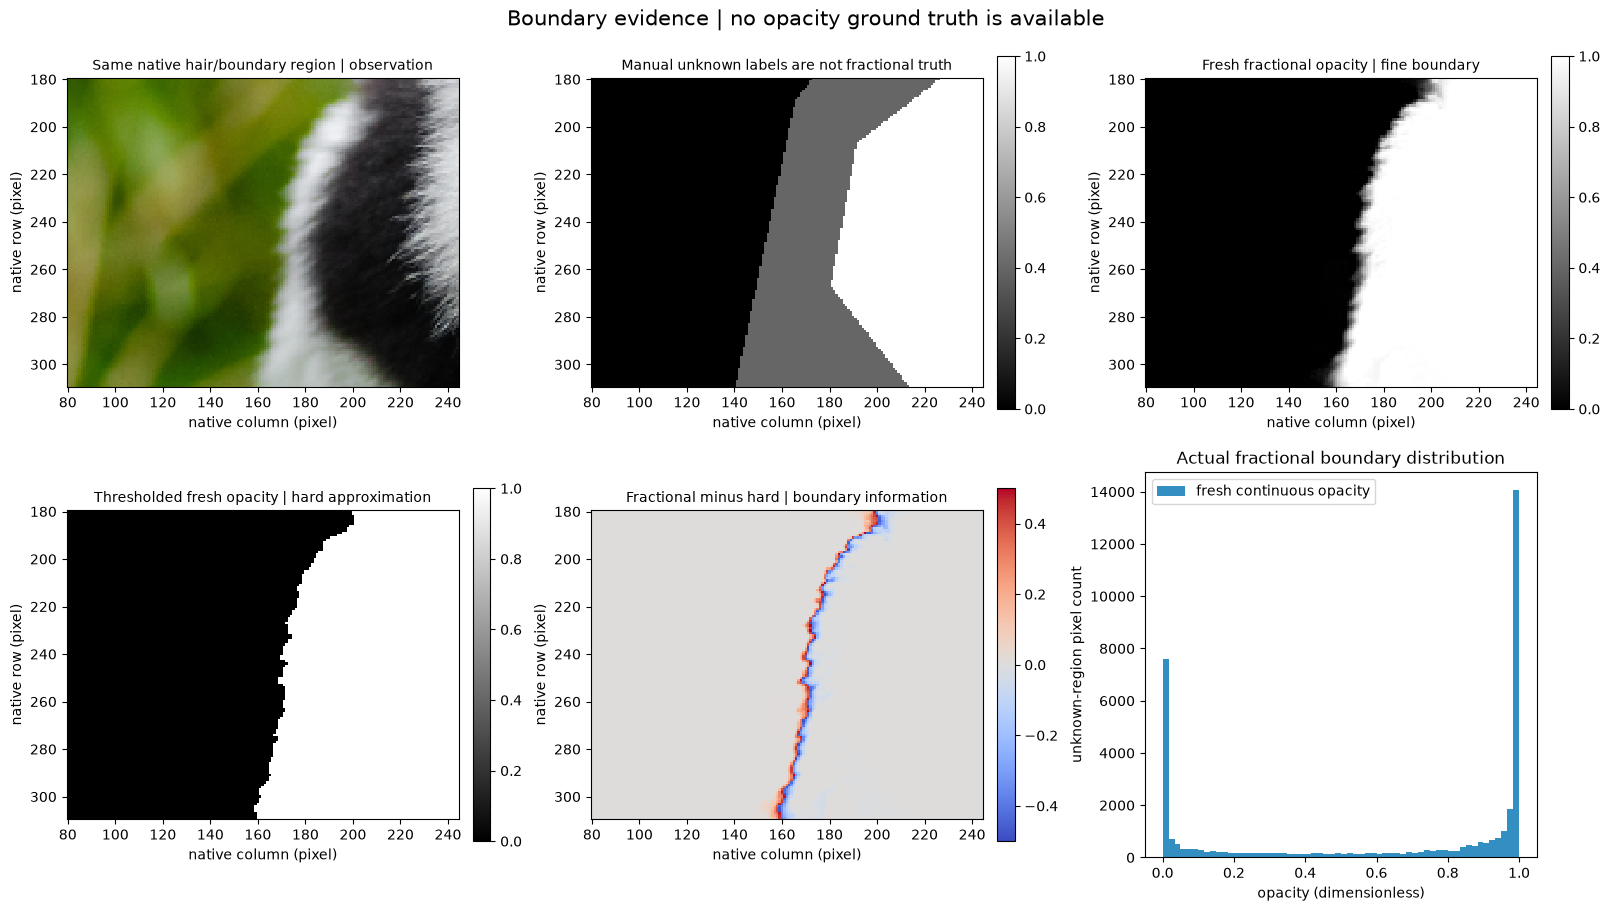

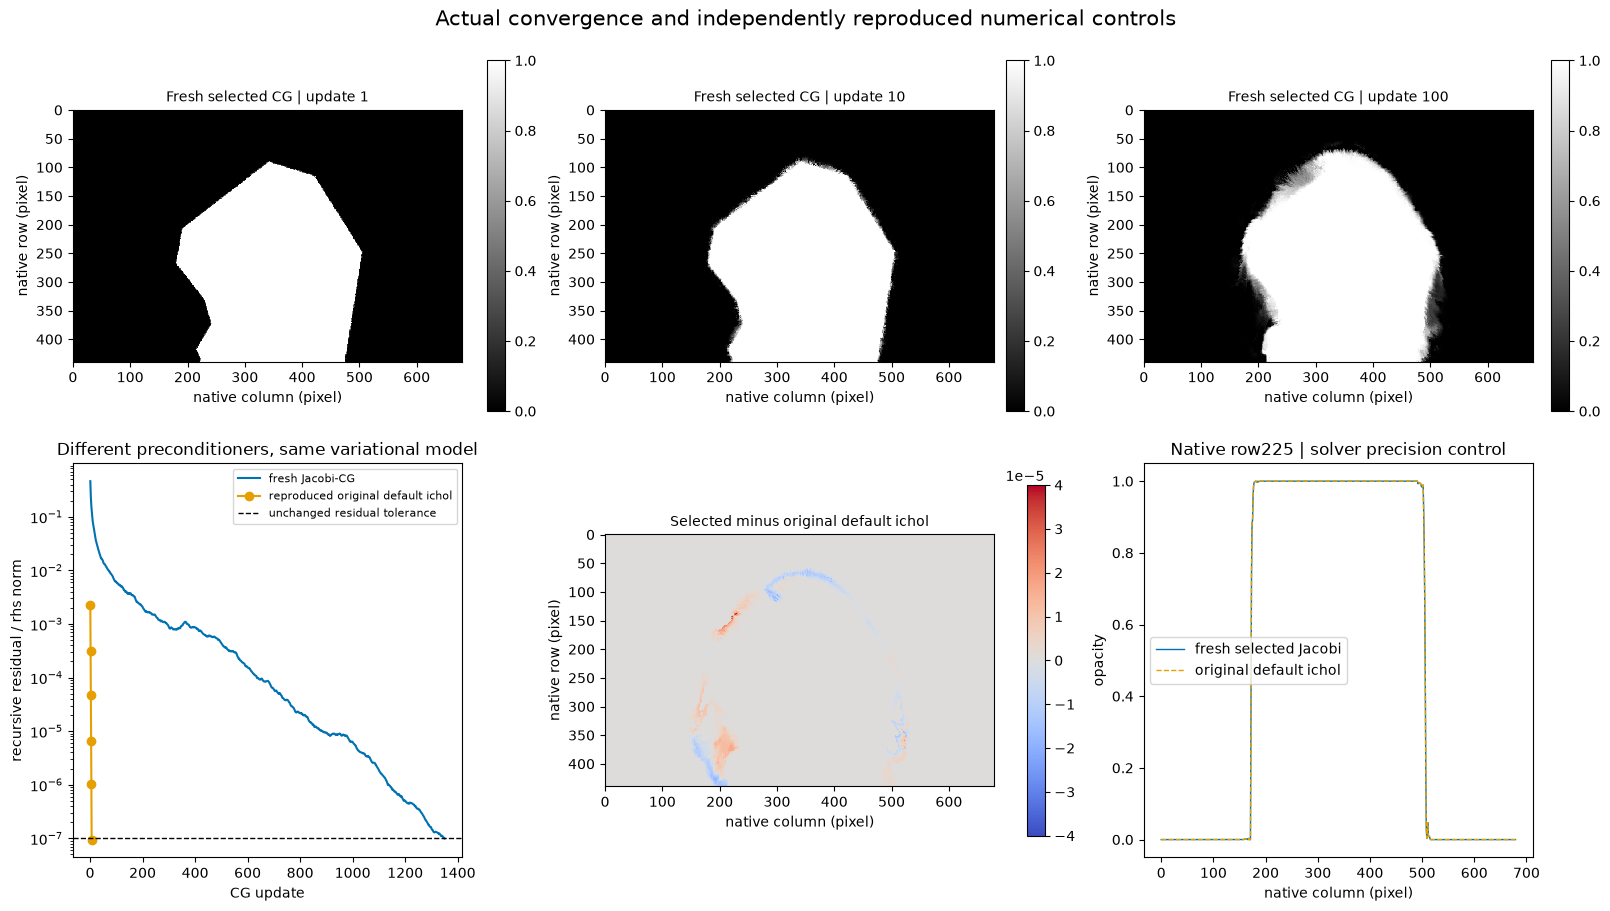

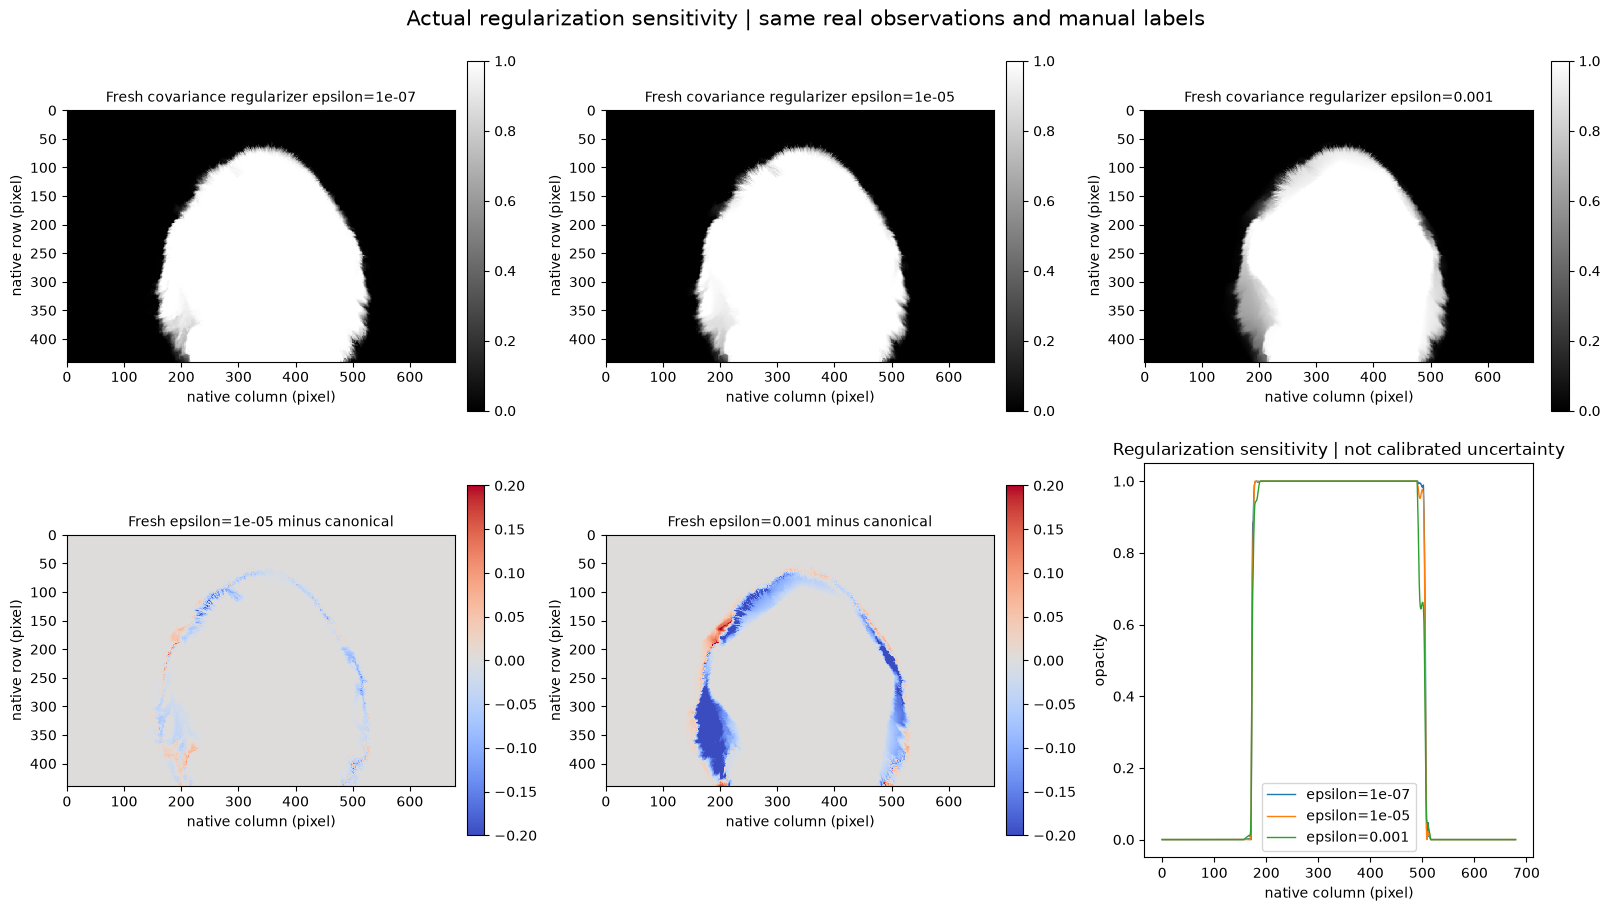

Private scientific figures and exact numeric sources: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch5_20261021\root\pymatting\final_figures


In [3]:
figures,numeric,measurements=make_figures(image,trimap,alpha,diagnostics,reference,default_reference,default_history)
measurements['active_standard_seconds']=active_seconds
print(json.dumps(measurements,indent=2))
for fig in figures:
    display(fig)
    plt.close(fig)
figure_dir=os.environ.get('IMAGING101_FIGURE_DIR')
if figure_dir:
    export_figures(figures,numeric,measurements,figure_dir)
    print('Private scientific figures and exact numeric sources:',figure_dir)


## 6. Conclusion

### Conclusion and scientific limits

The fresh full-resolution field matches the selected original numerical estimator and honors every independent known-opacity label. It preserves fractional hair/boundary information lost by a binary threshold. Different regularizers and mathematically equivalent iterative solves show why reference agreement must not be confused with measured opacity accuracy. The original default-preconditioner result is a numerical control, not truth; there is no hidden physical alpha measurement for this scene. Separate foreground/background colors remain underdetermined, and no decontaminated foreground or background-replacement quality is claimed. This one real photograph does not establish cross-scene generalization.

References: Levin, Lischinski and Weiss, CVPR2006 (author-hosted eight-page paper); Germer et al., JOSS2020, DOI10.21105/joss.02481; PyMatting source revision6d5c4a6bed0e5672abac0bad078e594423ffe4fd. Modern code authors differ from the2006 algorithm authors. Photograph: Mathias Appel, CC0. See test/validation.md for exact provenance, independent original commands, mathematical tests and all completion gates.

The manual trimap supplies hard labels only at known foreground/background pixels. Fractional hair structure and regularization sensitivity concern an estimated alpha field, without measured alpha truth. Post-solve clipping is retained and is distinct from a box-constrained quadratic optimum.
